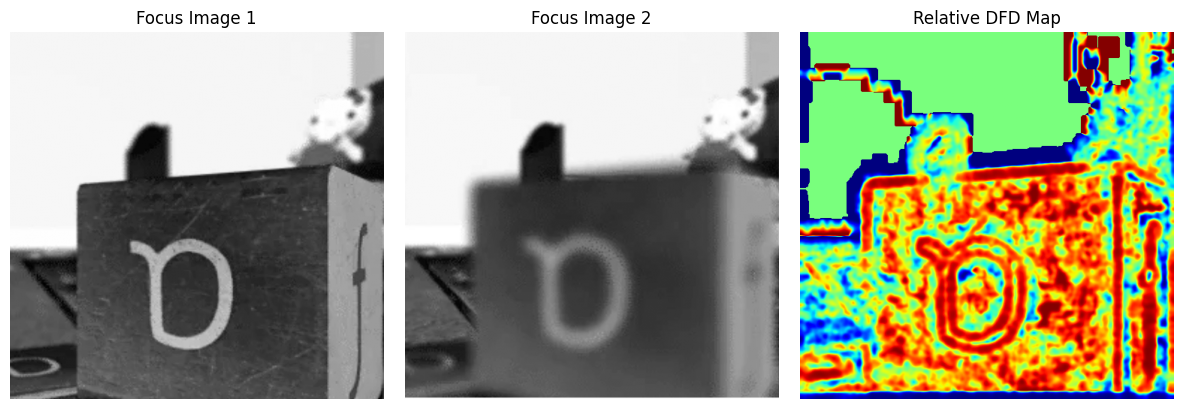

True

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the two images captured at different focus settings
img1 = cv2.imread("focus_near.png", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("focus_far.png", cv2.IMREAD_GRAYSCALE)

# 2. Check that both images were loaded
if img1 is None or img2 is None:
    raise FileNotFoundError("Check the image names and file paths.")

# 3. Make both images the same size
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

# 4. Apply a small Gaussian blur to reduce sensor noise
img1_s = cv2.GaussianBlur(img1, (3, 3), 0)
img2_s = cv2.GaussianBlur(img2, (3, 3), 0)

# 5. Calculate the Laplacian response
lap1 = cv2.Laplacian(img1_s, cv2.CV_64F)
lap2 = cv2.Laplacian(img2_s, cv2.CV_64F)

# 6. Estimate local focus using squared Laplacian
kernel = (15, 15)
focus1 = cv2.GaussianBlur(lap1 ** 2, kernel, 0)
focus2 = cv2.GaussianBlur(lap2 ** 2, kernel, 0)

# 7. Compare the focus measures
eps = 1e-8
focus_diff = (focus1 - focus2) / (focus1 + focus2 + eps)

# 8. Convert the relative focus difference into a displayable map
depth_map = cv2.normalize(focus_diff, None, 0, 255,
                          cv2.NORM_MINMAX).astype(np.uint8)

# 9. Display the input images and the DFD result
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img1, cmap="gray")
plt.title("Focus Image 1")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(img2, cmap="gray")
plt.title("Focus Image 2")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(depth_map, cmap="jet")
plt.title("Relative DFD Map")
plt.axis("off")

plt.tight_layout()
plt.show()

# 10. Save the result
cv2.imwrite("dfd_relative_depth.png", depth_map)


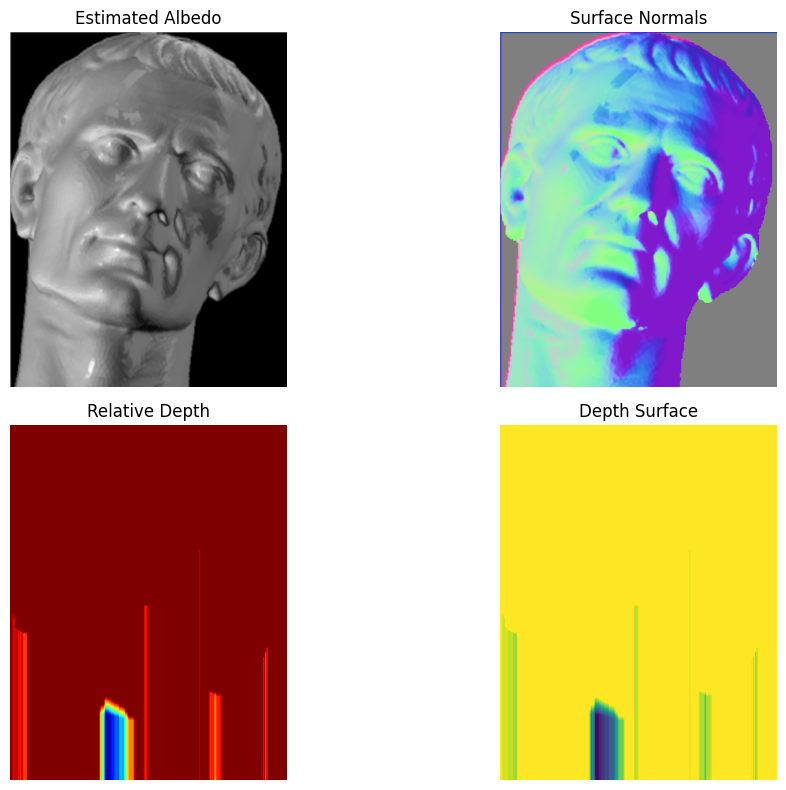

True

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read four grayscale images of the same object
files = ["light1.png", "light2.png", "light3.png", "light4.png"]

images = []
target_shape = None
for f in files:
    img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read {f}")

    # Establish the target shape from the first image
    if target_shape is None:
        target_shape = (img.shape[1], img.shape[0])  # (width, height)
    else:
        # Resize to match the target shape if different
        if (img.shape[1], img.shape[0]) != target_shape:
            img = cv2.resize(img, target_shape)

    images.append(img.astype(np.float64) / 255.0)

# 2. Stack the images: shape = (number_of_images, height, width)
I = np.stack(images, axis=0)

# 3. Known light directions [lx, ly, lz]
# Replace these with the directions used during your own capture.
L = np.array([
    [ 0.0,  0.0, 1.0],
    [ 0.6,  0.0, 0.8],
    [-0.6,  0.0, 0.8],
    [ 0.0,  0.6, 0.8]
], dtype=np.float64)

# 4. Normalize every light direction
L = L / np.linalg.norm(L, axis=1, keepdims=True)

# 5. Compute the pseudo-inverse of the lighting matrix
L_pinv = np.linalg.pinv(L)

# 6. Rearrange image data so each pixel has an intensity vector
m, h, w = I.shape
I_pixels = I.reshape(m, -1)

# 7. Estimate scaled surface normals g = L+ I
G = L_pinv @ I_pixels

# 8. Calculate albedo = magnitude of the scaled normal
albedo = np.linalg.norm(G, axis=0)

# 9. Normalize G to obtain unit surface normals
normals = G / (albedo[None, :] + 1e-8)

# 10. Extract normal components
nx = normals[0].reshape(h, w)
ny = normals[1].reshape(h, w)
nz = normals[2].reshape(h, w)

# 11. Convert normals to surface gradients
p = -nx / (nz + 1e-8)
q = -ny / (nz + 1e-8)

# 12. Simple path integration to obtain a relative depth map
depth = np.zeros((h, w), dtype=np.float64)

# Integrate p along x direction
for y in range(h):
    depth[y, 1:] = np.cumsum(p[y, :-1])

# Add q contribution along y direction
for x in range(w):
    depth[1:, x] += np.cumsum(q[:-1, x])

# 13. Normalize depth only for visualization
depth_vis = cv2.normalize(depth, None, 0, 255,
                          cv2.NORM_MINMAX).astype(np.uint8)

# 14. Normalize albedo for visualization
albedo_vis = cv2.normalize(albedo.reshape(h, w), None, 0, 255,
                           cv2.NORM_MINMAX).astype(np.uint8)

# 15. Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(albedo_vis, cmap="gray")
plt.title("Estimated Albedo")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(np.dstack([
    (nx + 1) / 2,
    (ny + 1) / 2,
    (nz + 1) / 2
]))
plt.title("Surface Normals")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(depth_vis, cmap="jet")
plt.title("Relative Depth")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(depth, cmap="viridis")
plt.title("Depth Surface")
plt.axis("off")

plt.tight_layout()
plt.show()

# 16. Save outputs
cv2.imwrite("photometric_albedo.png", albedo_vis)
cv2.imwrite("photometric_depth.png", depth_vis)

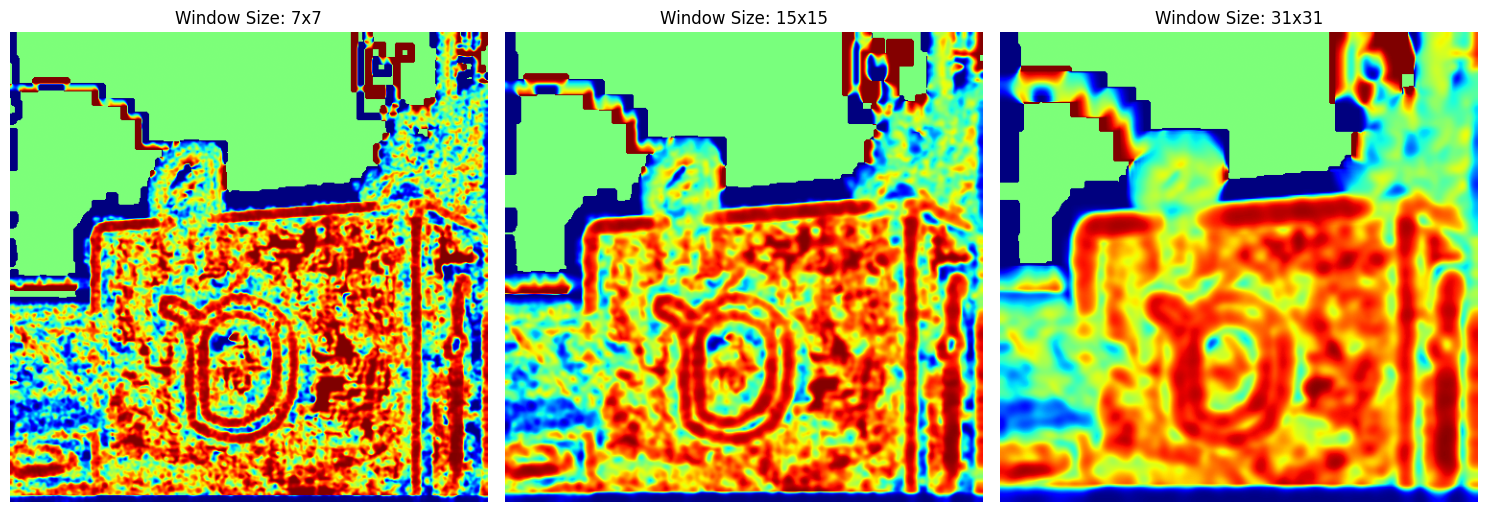

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read and prepare images as before
img1 = cv2.imread("focus_near.png", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("focus_far.png", cv2.IMREAD_GRAYSCALE)
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

# 2. Gaussian blur and Laplacian
img1_s = cv2.GaussianBlur(img1, (3, 3), 0)
img2_s = cv2.GaussianBlur(img2, (3, 3), 0)
lap1 = cv2.Laplacian(img1_s, cv2.CV_64F)
lap2 = cv2.Laplacian(img2_s, cv2.CV_64F)

# 3. Define the kernels to compare
kernels = [(7, 7), (15, 15), (31, 31)]
results = []

for k in kernels:
    focus1 = cv2.GaussianBlur(lap1 ** 2, k, 0)
    focus2 = cv2.GaussianBlur(lap2 ** 2, k, 0)

    eps = 1e-8
    focus_diff = (focus1 - focus2) / (focus1 + focus2 + eps)

    depth_map = cv2.normalize(focus_diff, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    results.append(depth_map)

# 4. Plot the comparison
plt.figure(figsize=(15, 5))
for i, (k, result) in enumerate(zip(kernels, results)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(result, cmap="jet")
    plt.title(f"Window Size: {k[0]}x{k[1]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Comparison of DFD Window Sizes

- **7x7 Window:** Captures highly localized focus changes. However, it is very susceptible to high-frequency image noise, leading to a pixelated and noisy depth map.
- **15x15 Window:** A balanced approach that provides moderate smoothing while retaining the general shape boundaries of the foreground object.
- **31x31 Window:** Results in a very smooth map.

#### Why a larger window is smoother but less localized:
1. **Smoothness:** A larger Gaussian window acts as a stronger low-pass filter, averaging the squared Laplacian values over a broader neighborhood. This averages out high-frequency noise variations, making the resulting depth transitions look continuous.
2. **Loss of Localization (Edge Bleeding):** When the window is large, the focus measure of pixels near depth boundaries is computed using a mixture of foreground and background textures. This causes the boundary transitions to "bleed" or smear across the depth discontinuities, making it harder to pinpoint the exact location of structural edges.

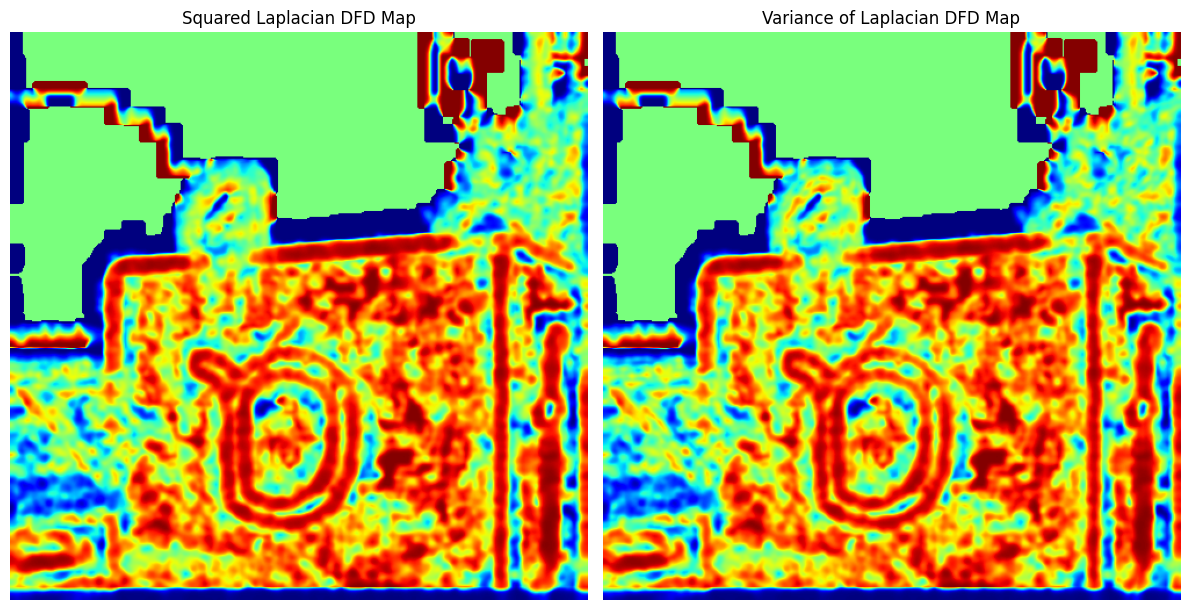

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load images and calculate Laplacians as before
img1 = cv2.imread("focus_near.png", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("focus_far.png", cv2.IMREAD_GRAYSCALE)
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

img1_s = cv2.GaussianBlur(img1, (3, 3), 0)
img2_s = cv2.GaussianBlur(img2, (3, 3), 0)

lap1 = cv2.Laplacian(img1_s, cv2.CV_64F)
lap2 = cv2.Laplacian(img2_s, cv2.CV_64F)

# 2. Focus Measure 1: Squared Laplacian (Main Program)
kernel_size = (15, 15)
focus1_sq = cv2.GaussianBlur(lap1 ** 2, kernel_size, 0)
focus2_sq = cv2.GaussianBlur(lap2 ** 2, kernel_size, 0)

eps = 1e-8
dfd_sq = (focus1_sq - focus2_sq) / (focus1_sq + focus2_sq + eps)
depth_sq = cv2.normalize(dfd_sq, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 3. Focus Measure 2: Variance of Laplacian
# Var(X) = E[X^2] - (E[X])^2
mean1 = cv2.GaussianBlur(lap1, kernel_size, 0)
mean2 = cv2.GaussianBlur(lap2, kernel_size, 0)

var1 = cv2.GaussianBlur(lap1 ** 2, kernel_size, 0) - (mean1 ** 2)
var2 = cv2.GaussianBlur(lap2 ** 2, kernel_size, 0) - (mean2 ** 2)

# Ensure variance is strictly non-negative
var1 = np.maximum(var1, 0)
var2 = np.maximum(var2, 0)

dfd_var = (var1 - var2) / (var1 + var2 + eps)
depth_var = cv2.normalize(dfd_var, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 4. Display comparisons
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(depth_sq, cmap="jet")
plt.title("Squared Laplacian DFD Map")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth_var, cmap="jet")
plt.title("Variance of Laplacian DFD Map")
plt.axis("off")

plt.tight_layout()
plt.show()

### Comparison of Focus Measures

- **Squared Laplacian ($\sum L^2$):** Measures the overall energy of high frequencies (edges/texture) in the local window. It is highly sensitive to strong gradients, but can sometimes be biased by local brightness changes or baseline offsets.
- **Variance of Laplacian ($E[L^2] - (E[L])^2$):** Computes the variance of the high-frequency components. By subtracting the local mean of the Laplacian, it removes any DC offset or slowly-varying lighting biases present in the window. This makes the variance-based measure more robust to uniform lighting gradients across the image patches, often yielding cleaner boundary delineations at depth transitions.

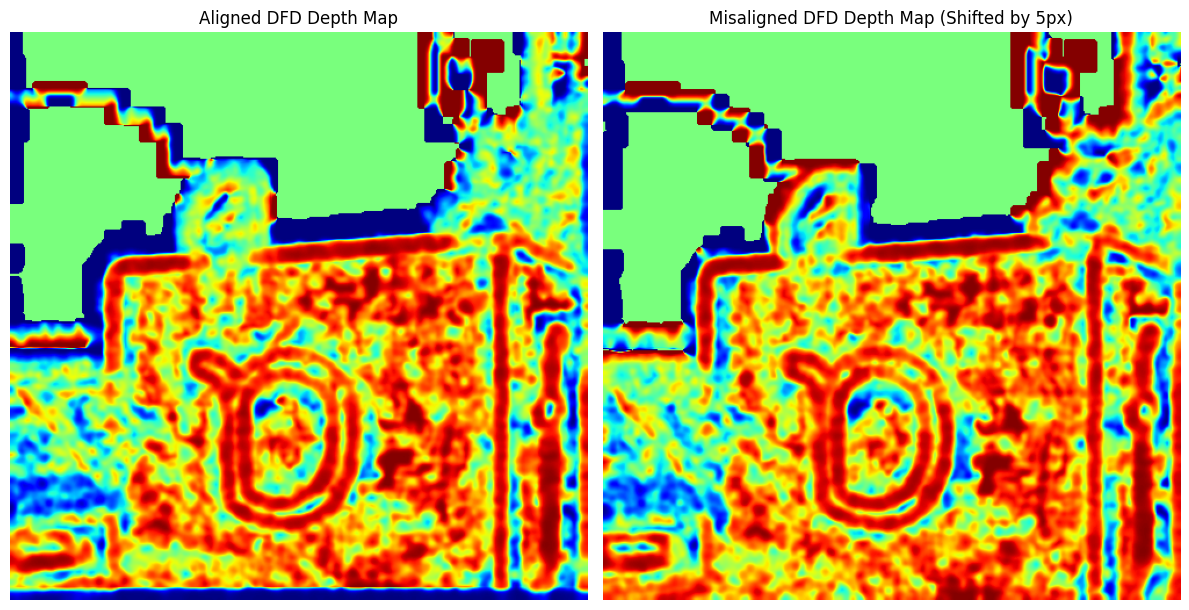

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load and resize images as before
img1 = cv2.imread("focus_near.png", cv2.IMREAD_GRAYSCALE)
img2_orig = cv2.imread("focus_far.png", cv2.IMREAD_GRAYSCALE)
img2_orig = cv2.resize(img2_orig, (img1.shape[1], img1.shape[0]))

# 2. Shift img2 by 5 pixels horizontally and vertically to simulate misalignment
shift_x, shift_y = 5, 5
M = np.float32([[1, 0, shift_x], [0, 1, shift_y]])
img2_shifted = cv2.warpAffine(img2_orig, M, (img1.shape[1], img1.shape[0]), borderMode=cv2.BORDER_REPLICATE)

# 3. Helper function to compute DFD depth map
def compute_dfd(image1, image2, kernel_size=(15, 15)):
    i1_s = cv2.GaussianBlur(image1, (3, 3), 0)
    i2_s = cv2.GaussianBlur(image2, (3, 3), 0)

    l1 = cv2.Laplacian(i1_s, cv2.CV_64F)
    l2 = cv2.Laplacian(i2_s, cv2.CV_64F)

    f1 = cv2.GaussianBlur(l1 ** 2, kernel_size, 0)
    f2 = cv2.GaussianBlur(l2 ** 2, kernel_size, 0)

    eps = 1e-8
    diff = (f1 - f2) / (f1 + f2 + eps)
    return cv2.normalize(diff, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 4. Compute aligned and misaligned depth maps
depth_aligned = compute_dfd(img1, img2_orig)
depth_misaligned = compute_dfd(img1, img2_shifted)

# 5. Display the comparison
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(depth_aligned, cmap="jet")
plt.title("Aligned DFD Depth Map")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth_misaligned, cmap="jet")
plt.title("Misaligned DFD Depth Map (Shifted by 5px)")
plt.axis("off")

plt.tight_layout()
plt.show()

### Explanation: Why Alignment is Crucial for DFD

Depth from Defocus (DFD) works under the fundamental assumption that any change in local high-frequency content (detected via the Laplacian operator) between the two frames is purely due to a change in **optical defocus** (blur).

When camera motion, object motion, or misalignment occurs between exposures, it introduces structural mismatches:

1. **False Edge Detection (Ghosting):** Shifting one image causes physical features (like edges) to appear at different pixel coordinates in each frame. When we evaluate the pixel-wise difference of local focus measures, the algorithm compares an edge in Image 1 to a flat or different region in Image 2. This creates artificial "halo" artifacts, or ghost boundaries.
2. **False Depth Signals:** The algorithm interprets the structural mismatch as a massive difference in high-frequency energy. This causes it to falsely calculate extreme depth values (saturated blue or red values along boundaries) that do not exist in the actual scene.
3. **Violation of Pixel Coherence:** DFD expects a strict one-to-one mapping where $(x, y)$ in the first image corresponds exactly to the same physical point $(x, y)$ in the second image. Thus, any active movement or vibration ruins the mathematical model, highlighting the necessity of sub-pixel level image registration in real-world DFD setups.

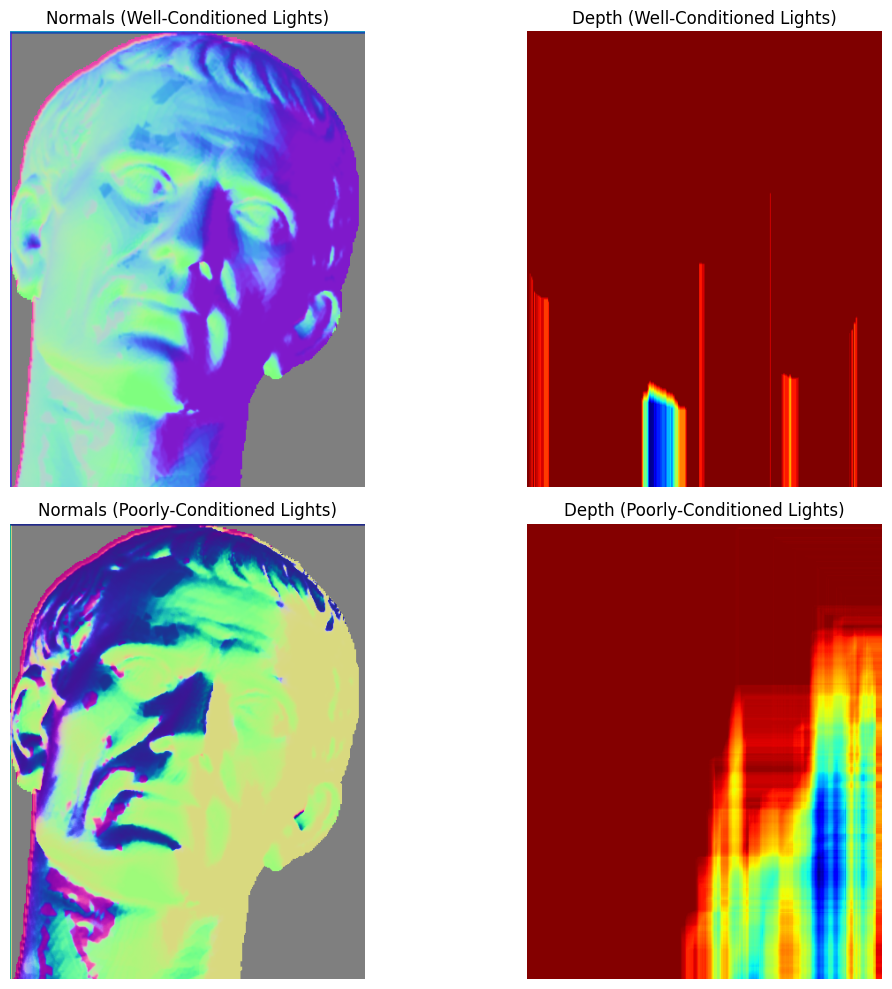

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the original light images
files = ["light1.png", "light2.png", "light3.png", "light4.png"]
images = []
target_shape = None
for f in files:
    img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read {f}")
    if target_shape is None:
        target_shape = (img.shape[1], img.shape[0])
    else:
        if (img.shape[1], img.shape[0]) != target_shape:
            img = cv2.resize(img, target_shape)
    images.append(img.astype(np.float64) / 255.0)

I = np.stack(images, axis=0)
m, h, w = I.shape
I_pixels = I.reshape(m, -1)

# 2. Setup Configuration A: Well-conditioned (Original wide-spread configuration)
L_well = np.array([
    [ 0.0,  0.0, 1.0],
    [ 0.6,  0.0, 0.8],
    [-0.6,  0.0, 0.8],
    [ 0.0,  0.6, 0.8]
], dtype=np.float64)
L_well = L_well / np.linalg.norm(L_well, axis=1, keepdims=True)

# Setup Configuration B: Poorly-conditioned (Closely grouped, co-planar directions)
# This simulates lights that are too close to each other, offering little angular diversity
L_poor = np.array([
    [ 0.05,  0.05, 0.99],
    [ 0.10,  0.00, 0.99],
    [-0.05,  0.05, 0.99],
    [ 0.00,  0.10, 0.99]
], dtype=np.float64)
L_poor = L_poor / np.linalg.norm(L_poor, axis=1, keepdims=True)

def reconstruct_photometric_stereo(I_pix, L_matrix, height, width):
    L_pinv = np.linalg.pinv(L_matrix)
    G = L_pinv @ I_pix
    albedo = np.linalg.norm(G, axis=0)
    normals = G / (albedo[None, :] + 1e-8)

    nx = normals[0].reshape(height, width)
    ny = normals[1].reshape(height, width)
    nz = normals[2].reshape(height, width)

    # Gradient and integration
    p = -nx / (nz + 1e-8)
    q = -ny / (nz + 1e-8)
    depth = np.zeros((height, width), dtype=np.float64)
    for y in range(height):
        depth[y, 1:] = np.cumsum(p[y, :-1])
    for x in range(width):
        depth[1:, x] += np.cumsum(q[:-1, x])

    depth_vis = cv2.normalize(depth, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    normal_vis = np.dstack([(nx + 1) / 2, (ny + 1) / 2, (nz + 1) / 2])
    return normal_vis, depth_vis

# Run both reconstructions
normals_well, depth_well = reconstruct_photometric_stereo(I_pixels, L_well, h, w)
normals_poor, depth_poor = reconstruct_photometric_stereo(I_pixels, L_poor, h, w)

# Plot the comparison
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(normals_well)
plt.title("Normals (Well-Conditioned Lights)")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(depth_well, cmap="jet")
plt.title("Depth (Well-Conditioned Lights)")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(normals_poor)
plt.title("Normals (Poorly-Conditioned Lights)")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(depth_poor, cmap="jet")
plt.title("Depth (Poorly-Conditioned Lights)")
plt.axis("off")

plt.tight_layout()
plt.show()

### Explanation: Why the Choice of Light Directions Matters

Photometric Stereo relies on solving a system of linear equations ($I = L \cdot G$) for each pixel. For this linear system to be solved accurately and robustly, the choice of light directions ($L$) is critical:

1. **Conditioning of the Light Matrix ($L$):** If the light directions are widespread (angularly diverse), the matrix $L$ is well-conditioned. If the light directions are nearly parallel or co-planar (as simulated in the poorly-conditioned setup), the matrix $L$ becomes nearly singular (having a very high condition number). Small amounts of sensor noise are then highly amplified during pseudo-inverse computation ($L^{\dagger}$), corrupting the estimated surface gradients ($p, q$).
2. **Angular Span vs. Shadows:**
   - **Too Narrow (Clustered):** If the lights are too close to the viewing axis, there is insufficient change in shading (shading intensity) across the frames. The system cannot distinguish between surface slopes pointing left vs. right, resulting in flat, noisy, or completely incorrect normal maps.
   - **Too Wide (Oblique):** If the light directions are extremely shallow (oblique angles), they create massive shadows (cast shadows and self-shadows). Shadows violate the Lambertian reflectance assumption ($I = \rho (N \cdot L)$), leading to severe distortions in both albedo and depth maps.
3. **Bas-Relief Ambiguity:** Under poorly distributed lighting setups, the algorithm cannot uniquely decouple the scaling of the depth magnitude, leading to flattened or highly exaggerated physical structures in the relative depth surface.

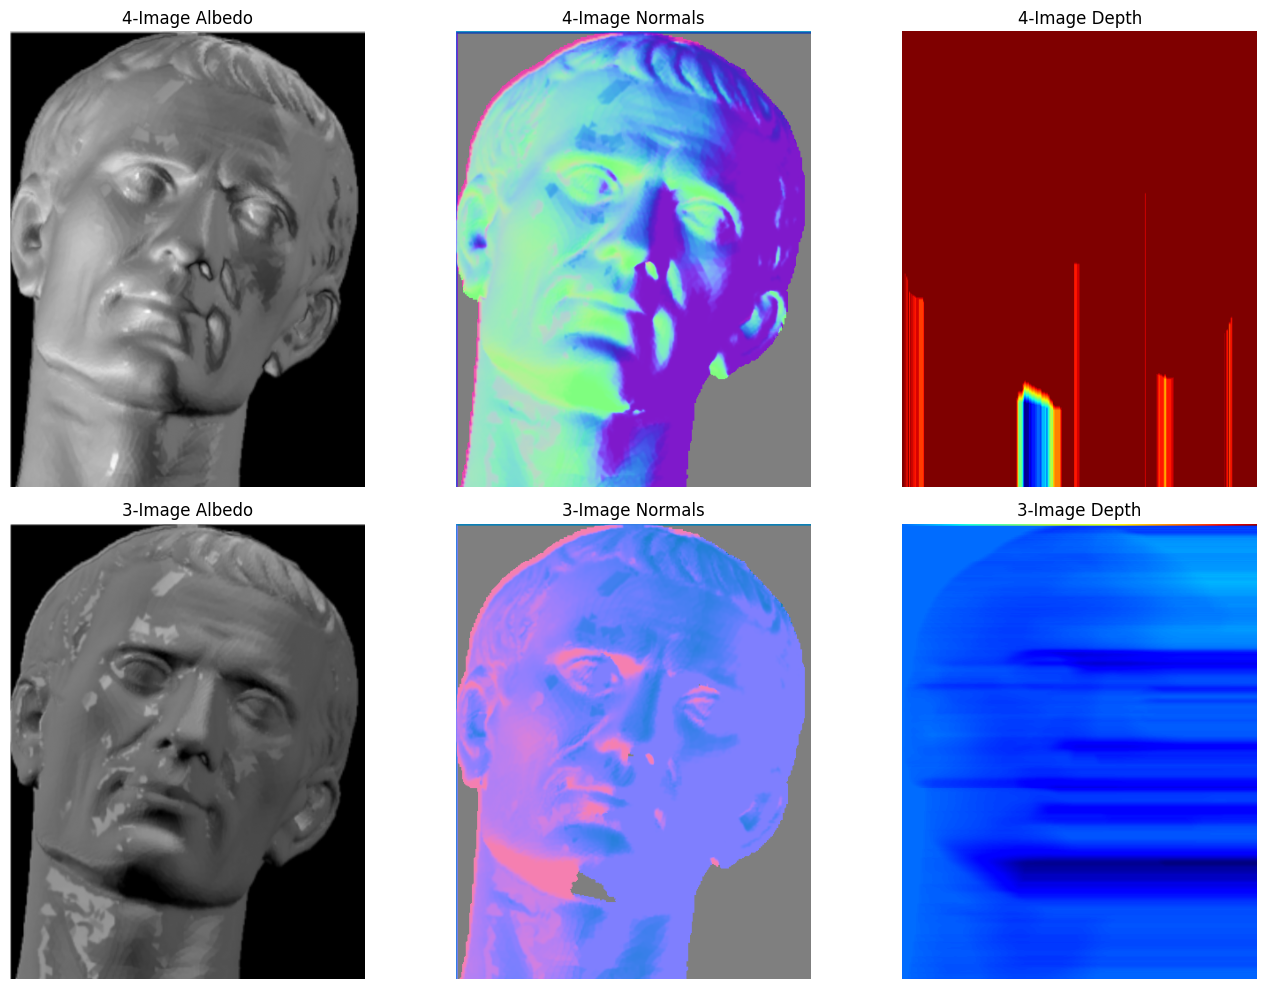

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the four original light images
files = ["light1.png", "light2.png", "light3.png", "light4.png"]
images = []
target_shape = None
for f in files:
    img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read {f}")
    if target_shape is None:
        target_shape = (img.shape[1], img.shape[0])
    else:
        if (img.shape[1], img.shape[0]) != target_shape:
            img = cv2.resize(img, target_shape)
    images.append(img.astype(np.float64) / 255.0)

# Prepare baseline 4 images
I_4 = np.stack(images, axis=0)
m_4, h, w = I_4.shape
I_pixels_4 = I_4.reshape(m_4, -1)

# Prepare 3 images (using first three)
I_3 = np.stack(images[:3], axis=0)
m_3 = 3
I_pixels_3 = I_3.reshape(m_3, -1)

# 2. Setup lighting matrices
L_all = np.array([
    [ 0.0,  0.0, 1.0],
    [ 0.6,  0.0, 0.8],
    [-0.6,  0.0, 0.8],
    [ 0.0,  0.6, 0.8]
], dtype=np.float64)
L_all = L_all / np.linalg.norm(L_all, axis=1, keepdims=True)

L_4 = L_all
L_3 = L_all[:3]

# 3. Define reconstruction function
def reconstruct(I_pix, L_mat, height, width):
    L_pinv = np.linalg.pinv(L_mat)
    G = L_pinv @ I_pix
    albedo = np.linalg.norm(G, axis=0)
    normals = G / (albedo[None, :] + 1e-8)

    nx = normals[0].reshape(height, width)
    ny = normals[1].reshape(height, width)
    nz = normals[2].reshape(height, width)

    # Gradient and integration
    p = -nx / (nz + 1e-8)
    q = -ny / (nz + 1e-8)
    depth = np.zeros((height, width), dtype=np.float64)
    for y in range(height):
        depth[y, 1:] = np.cumsum(p[y, :-1])
    for x in range(width):
        depth[1:, x] += np.cumsum(q[:-1, x])

    depth_vis = cv2.normalize(depth, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    normal_vis = np.dstack([(nx + 1) / 2, (ny + 1) / 2, (nz + 1) / 2])
    albedo_vis = cv2.normalize(albedo.reshape(height, width), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return albedo_vis, normal_vis, depth_vis

# Run reconstructions
alb_4, norm_4, dep_4 = reconstruct(I_pixels_4, L_4, h, w)
alb_3, norm_3, dep_3 = reconstruct(I_pixels_3, L_3, h, w)

# 4. Display comparisons
plt.figure(figsize=(14, 10))

# Row 1: 4-Image Setup
plt.subplot(2, 3, 1)
plt.imshow(alb_4, cmap="gray")
plt.title("4-Image Albedo")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(norm_4)
plt.title("4-Image Normals")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(dep_4, cmap="jet")
plt.title("4-Image Depth")
plt.axis("off")

# Row 2: 3-Image Setup
plt.subplot(2, 3, 4)
plt.imshow(alb_3, cmap="gray")
plt.title("3-Image Albedo")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(norm_3)
plt.title("3-Image Normals")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(dep_3, cmap="jet")
plt.title("3-Image Depth")
plt.axis("off")

plt.tight_layout()
plt.show()

### Explanation: The Effect of Fewer Images on Robustness

Mathematically, since a 3D surface normal $\mathbf{n}$ has 3 degrees of freedom (accounting for the unknown albedo $\rho$), we need a minimum of **3 independent equations** to solve for the scaled normal vector $\mathbf{G}$. This makes Photometric Stereo with 3 images a **critically determined** system.

Reducing the image count from 4 to 3 has direct, negative impacts on system robustness:

1. **Zero Tolerance for Shadows and Specularities:** In a 3-image setup, if even a single pixel falls into a shadow (cast shadow or self-shadow) or exhibits specular highlights in one of the frames, the Lambertian assumption ($I = \rho (\mathbf{n} \cdot \mathbf{l})$) fails. Because there is no redundant information, this local error propagates completely into the estimated normal and produces severe, sharp artifacts.
2. **No Noise Averaging:** With 4 or more images, the system is **overdetermined** ($M > 3$). Using the pseudo-inverse ($L^{\dagger}$) acts as a least-squares estimator, which averages out high-frequency sensor noise across the multiple frames. In a critically determined 3-image system, any sensor or photon noise directly distorts the estimated gradients.
3. **Illumination Coverage:** With only 3 light sources, some parts of highly curved objects may not receive adequate illumination from all three directions, creating dark regions where the matrix inversion is highly unstable.

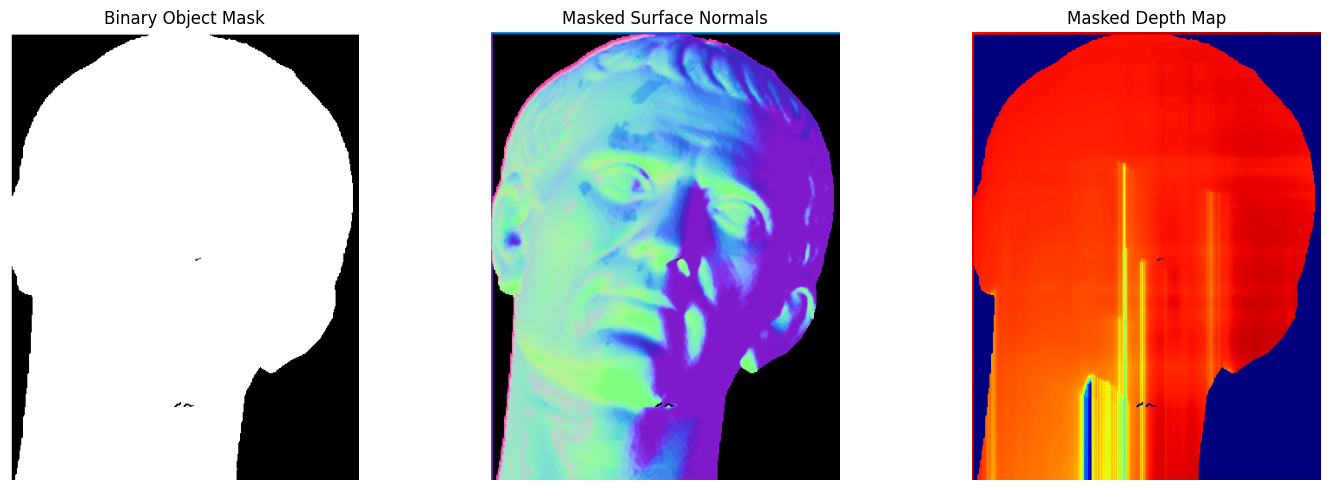

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the four original light images and stack them
files = ["light1.png", "light2.png", "light3.png", "light4.png"]
images = []
target_shape = None
for f in files:
    img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read {f}")
    if target_shape is None:
        target_shape = (img.shape[1], img.shape[0])
    else:
        if (img.shape[1], img.shape[0]) != target_shape:
            img = cv2.resize(img, target_shape)
    images.append(img.astype(np.float64) / 255.0)

I = np.stack(images, axis=0)
m, h, w = I.shape
I_pixels = I.reshape(m, -1)

# 2. Setup original lighting matrix and pseudo-inverse
L = np.array([
    [ 0.0,  0.0, 1.0],
    [ 0.6,  0.0, 0.8],
    [-0.6,  0.0, 0.8],
    [ 0.0,  0.6, 0.8]
], dtype=np.float64)
L = L / np.linalg.norm(L, axis=1, keepdims=True)
L_pinv = np.linalg.pinv(L)

# 3. Estimate scaled surface normals and albedo
G = L_pinv @ I_pixels
albedo = np.linalg.norm(G, axis=0).reshape(h, w)

# 4. Create a binary mask based on albedo intensity thresholding
# This isolates the object from the dark background
threshold = 0.05
binary_mask = (albedo > threshold).astype(np.uint8)

# 5. Compute normals inside the mask only (zero elsewhere)
normals = np.zeros((3, h * w), dtype=np.float64)
G_flat = G
albedo_flat = albedo.flatten()
valid_idx = albedo_flat > threshold

# Normalize only valid pixels to avoid division-by-zero or division-by-noise
normals[:, valid_idx] = G_flat[:, valid_idx] / albedo_flat[None, valid_idx]

nx_masked = normals[0].reshape(h, w)
ny_masked = normals[1].reshape(h, w)
nz_masked = normals[2].reshape(h, w)

# 6. Convert normals to gradients inside the mask only
p_masked = np.zeros((h, w), dtype=np.float64)
q_masked = np.zeros((h, w), dtype=np.float64)

# Avoid division by small nz values inside the valid region
nz_thresh = 1e-4
valid_nz = (binary_mask == 1) & (nz_masked > nz_thresh)

p_masked[valid_nz] = -nx_masked[valid_nz] / nz_masked[valid_nz]
q_masked[valid_nz] = -ny_masked[valid_nz] / nz_masked[valid_nz]

# 7. Path integration restricted to the binary mask
depth_masked = np.zeros((h, w), dtype=np.float64)
for y in range(h):
    # Integrate horizontally, propagating values only within the mask
    row_mask = binary_mask[y, :]
    p_row = p_masked[y, :]
    depth_masked[y, 1:] = np.cumsum(p_row[:-1]) * row_mask[1:]

for x in range(w):
    # Add vertical contribution, propagating values only within the mask
    col_mask = binary_mask[:, x]
    q_col = q_masked[:, x]
    depth_masked[1:, x] += np.cumsum(q_col[:-1]) * col_mask[1:]

# Force background depth to 0
depth_masked[binary_mask == 0] = 0

# Normalize for visualization
depth_vis_masked = cv2.normalize(depth_masked, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
depth_vis_masked[binary_mask == 0] = 0

normal_vis_masked = np.dstack([
    (nx_masked + 1) / 2,
    (ny_masked + 1) / 2,
    (nz_masked + 1) / 2
])
normal_vis_masked[binary_mask == 0] = 0

# 8. Display masked results side-by-side with binary mask
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(binary_mask, cmap="gray")
plt.title("Binary Object Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(normal_vis_masked)
plt.title("Masked Surface Normals")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(depth_vis_masked, cmap="jet")
plt.title("Masked Depth Map")
plt.axis("off")

plt.tight_layout()
plt.show()

### Explanation: Why Background Pixels Contaminate Reconstruction

Without an explicit mask, background pixels degrade and corrupt the reconstruction of the central object in several ways:

1. **Division by Zero/Noise Amplification:** Background regions often have an albedo value near zero. During normal estimation ($N = G / \|G\|$), dividing a very small vector by its norm amplifies random sensor noise, producing erratic and completely incorrect normal vectors (which manifest as random colors in the unmasked normal map).
2. **Extreme Gradients ($p, q$):** Gradients are computed as $p = -n_x / n_z$ and $q = -n_y / n_z$. In background regions where $n_z \approx 0$, these divisions yield massive or infinite gradients.
3. **Integration Error Leakage:** The depth map is calculated using path integration (cumulative summation of $p$ and $q$). If we do not mask the gradients, the massive, chaotic gradients from the background get accumulated and swept into the foreground object during the summation loops. This is what caused the severe horizontal and vertical streak artifacts in the unmasked relative depth plots.

### Task 7: Final Comparison between DFD and Photometric Stereo

| Feature | Depth From Defocus (DFD) | Photometric Stereo (PS) |
| :--- | :--- | :--- |
| **Primary Depth Cue** | Focus / Optical Defocus blur (high-frequency energy changes) | Shading changes under varying illumination directions |
| **Input Requirements** | At least **2 images** captured with different focus/aperture settings from a stationary camera. | At least **3 (preferably 4+) images** from a stationary camera with known, varying light source directions. |
| **Setup Complexity** | **Low:** Needs only standard focus adjustments on a camera lens. | **High:** Requires calibration of light source positions and controlled dark environments to avoid ambient light pollution. |
| **Strengths** | - Works on texture-rich, complex structures.<br>- Non-contact and simple sensor setups.<br>- Single-camera friendly. | - Recovers fine-grained surface details and local micro-textures.<br>- Outputs surface normals and reflective properties (albedo). |
| **Weaknesses** | - Fails on textureless or flat surfaces.<br>- Highly sensitive to sub-pixel camera/object misalignment.<br>- Blur propagation smooths out sharp structural boundaries. | - Fails under non-Lambertian surfaces (specularities, glass).<br>- Vulnerable to shadow cast anomalies.<br>- Requires dark, enclosed lighting environments. |
| **Type of Result** | Coarse, smoothed **relative/absolute depth maps** reflecting macroscopic distance. | High-frequency **surface normal fields** and fine-grained, localized **relative depth surfaces**. |